# 05 · Optimization, MLflow & Final Model

**Goal:** tune the models, measure the gain, evaluate the contribution of feature
engineering and of the `cluster` variable, compare all MLflow experiments and save the
final model.

| Step | Content |
| --- | --- |
| 1 | Performance **before** optimization (5-fold CV) |
| 2 | Hyperparameter tuning: `GridSearchCV` / `RandomizedSearchCV` |
| 3 | Before vs after comparison |
| 4 | Contribution of feature engineering and of the cluster |
| 5 | Final model: test evaluation + MLflow (model registry) |
| 6 | Compare all MLflow experiments |
| 7 | Save the model & predict a new customer |

## Setup
This notebook is **self-contained**: it reloads the raw CSV and redefines the cleaning,
feature-engineering and preprocessing steps (explained in detail in notebook 01), so it
can be run on its own.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA = ROOT / "data" / "raw" / "wa-fn-usec-telco-customer.csv"
MODELS_DIR = ROOT / "models"
MLFLOW_URI = f"sqlite:///{ROOT / 'mlflow.db'}"

RANDOM_STATE = 42
TARGET = "Churn"
ID_COLUMN = "customerID"

### Cleaning & feature engineering
- `clean_raw`: convert `TotalCharges` to numeric (blank → NaN) and drop duplicated profiles.
- `add_features`: row-wise engineered features (no learned statistic → no leakage).

In [2]:
SERVICE_COLUMNS = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                   "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]


def clean_raw(df):
    df = df.copy()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    return df.drop_duplicates(subset=[c for c in df.columns if c != ID_COLUMN]).reset_index(drop=True)


def add_features(df):
    df = df.copy()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df["num_services"] = (df[SERVICE_COLUMNS] == "Yes").sum(axis=1) + (df["InternetService"] != "No")
    df["avg_monthly_spend"] = np.where(df["tenure"] > 0,
                                       df["TotalCharges"] / df["tenure"].replace(0, np.nan),
                                       df["MonthlyCharges"])
    df["charges_per_service"] = df["MonthlyCharges"] / df["num_services"].clip(lower=1)
    df["is_month_to_month"] = (df["Contract"] == "Month-to-month").astype(int)
    df["auto_payment"] = df["PaymentMethod"].str.contains("automatic").astype(int)
    df["has_family"] = ((df["Partner"] == "Yes") | (df["Dependents"] == "Yes")).astype(int)
    df["is_new_customer"] = (df["tenure"] <= 6).astype(int)
    df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 60, 72],
                                labels=["0-12", "13-24", "25-48", "49-60", "61-72"]).astype(str)
    return df

### Preprocessing
Numeric → median imputation + standardization; binary → unchanged;
categorical → most-frequent imputation + one-hot encoding.

In [3]:
RAW_NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]
RAW_BINARY = ["SeniorCitizen"]
RAW_CATEGORICAL = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
                   "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                   "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
                   "PaperlessBilling", "PaymentMethod"]

NUMERIC_FEATURES = RAW_NUMERIC + ["num_services", "avg_monthly_spend", "charges_per_service"]
BINARY_FEATURES = RAW_BINARY + ["is_month_to_month", "auto_payment", "has_family", "is_new_customer"]
CATEGORICAL_FEATURES = RAW_CATEGORICAL + ["tenure_group"]

# Subset used for segmentation (no target!)
CLUSTER_NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges", "num_services"]
CLUSTER_BINARY = ["is_month_to_month", "auto_payment", "has_family", "SeniorCitizen"]
CLUSTER_CATEGORICAL = ["InternetService"]


def make_preprocessor(numeric=NUMERIC_FEATURES, binary=BINARY_FEATURES, categorical=CATEGORICAL_FEATURES):
    numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                             ("scaler", StandardScaler())])
    categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                 ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary",
                                                          sparse_output=False))])
    return ColumnTransformer([("num", numeric_pipe, numeric),
                              ("bin", "passthrough", binary),
                              ("cat", categorical_pipe, categorical)],
                             verbose_feature_names_out=False)

### Load data

In [4]:
df = clean_raw(pd.read_csv(RAW_DATA))
print("Dataset:", df.shape)

Dataset: (7021, 21)


### Modelling helpers
- `ClusterFeature`: adds the K-Means `cluster` (k = 4, see notebook 02) as a feature. The
  K-Means is **fitted on the training data only** (refitted on each CV fold).
- `build_pipeline`: raw customer rows → [feature engineering] → [cluster] → preprocessing →
  [oversampling] → model. Because everything lives in one `imblearn` pipeline, imputation,
  scaling and SMOTE/oversampling are fitted on training data only — **no data leakage** —
  and the oversampler is skipped at prediction time.

In [5]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

N_CLUSTERS = 4


def make_cluster_pipeline(n_clusters=N_CLUSTERS):
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("preprocess", make_preprocessor(CLUSTER_NUMERIC, CLUSTER_BINARY, CLUSTER_CATEGORICAL)),
        ("kmeans", KMeans(n_clusters=n_clusters, n_init=10, random_state=RANDOM_STATE)),
    ])


class ClusterFeature(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=N_CLUSTERS):
        self.n_clusters = n_clusters

    def fit(self, X, y=None):
        self.pipeline_ = make_cluster_pipeline(self.n_clusters).fit(X)
        return self

    def transform(self, X):
        X = X.copy()
        X["cluster"] = self.pipeline_.predict(X).astype(str)
        return X


MODEL_NAMES = ["LogisticRegression", "DecisionTree", "RandomForest", "SVM", "XGBoost"]
IMBALANCE_STRATEGIES = ["none", "class_weight", "random_oversampling", "smote"]


def make_model(name, strategy="none", pos_weight=1.0):
    cw = "balanced" if strategy == "class_weight" else None
    model = {
        "LogisticRegression": lambda: LogisticRegression(max_iter=2000, class_weight=cw),
        "DecisionTree": lambda: DecisionTreeClassifier(class_weight=cw, random_state=RANDOM_STATE),
        "RandomForest": lambda: RandomForestClassifier(n_estimators=300, class_weight=cw,
                                                       random_state=RANDOM_STATE, n_jobs=1),
        "SVM": lambda: SVC(class_weight=cw, random_state=RANDOM_STATE),
        "XGBoost": lambda: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                         eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1,
                                         scale_pos_weight=pos_weight if strategy == "class_weight" else 1.0),
    }[name]()
    sampler = {"random_oversampling": RandomOverSampler(random_state=RANDOM_STATE),
               "smote": SMOTE(random_state=RANDOM_STATE)}.get(strategy)
    return model, sampler


def build_pipeline(name, strategy="none", pos_weight=1.0, n_clusters=None, feature_engineering=True):
    model, sampler = make_model(name, strategy, pos_weight)
    steps = []
    if feature_engineering:
        steps.append(("features", FunctionTransformer(add_features)))
        num, binary, cat = NUMERIC_FEATURES, BINARY_FEATURES, CATEGORICAL_FEATURES
    else:
        num, binary, cat = RAW_NUMERIC, RAW_BINARY, RAW_CATEGORICAL
    if n_clusters:
        steps.append(("cluster", ClusterFeature(n_clusters)))
        cat = cat + ["cluster"]
    steps.append(("preprocess", make_preprocessor(num, binary, cat)))
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("model", model))
    return ImbPipeline(steps)


def predict_scores(model, X):
    """Churn probability, or decision score for SVM (enough for ROC-AUC)."""
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)


def evaluate(model, X, y):
    y_pred = model.predict(X)
    return {"precision": precision_score(y, y_pred), "recall": recall_score(y, y_pred),
            "f1": f1_score(y, y_pred), "roc_auc": roc_auc_score(y, predict_scores(model, X))}


def cv_scores(pipeline, X, y, cv):
    scores = cross_validate(pipeline, X, y, cv=cv, n_jobs=-1,
                            scoring=["precision", "recall", "f1", "roc_auc"])
    return {m: scores[f"test_{m}"].mean() for m in ["precision", "recall", "f1", "roc_auc"]}

### Train / test split
Same stratified 80/20 split (same `random_state`) in every notebook. The test set is
only used for the final evaluation; model selection uses 5-fold cross-validation on train.

In [6]:
X = df.drop(columns=[ID_COLUMN, TARGET])
y = (df[TARGET] == "Yes").astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()   # for XGBoost scale_pos_weight
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"Train {X_train.shape}, Test {X_test.shape}, churn rate train {y_train.mean():.3f}")

Train (5616, 19), Test (1405, 19), churn rate train 0.264


### MLflow helpers
Each run logs: model hyperparameters, preprocessing parameters, metrics, figures and the
fitted pipeline. Runs are stored in `mlflow.db` / `mlruns/` at the project root
(UI: `mlflow ui --backend-store-uri sqlite:///mlflow.db`).

In [7]:
import logging

import mlflow
import mlflow.sklearn

logging.getLogger("mlflow").setLevel(logging.ERROR)


def setup_mlflow(experiment_name):
    mlflow.set_tracking_uri(MLFLOW_URI)
    if mlflow.get_experiment_by_name(experiment_name) is None:
        mlflow.create_experiment(experiment_name,
                                 artifact_location=(ROOT / "mlruns" / experiment_name).as_uri())
    mlflow.set_experiment(experiment_name)


def preprocessing_params(pipeline):
    steps = dict(pipeline.steps)
    return {"feature_engineering": "features" in steps, "cluster_feature": "cluster" in steps,
            "numeric_imputer": "median", "categorical_imputer": "most_frequent",
            "scaler": "StandardScaler", "encoder": "OneHotEncoder",
            "resampling": type(steps["sampler"]).__name__ if "sampler" in steps else "none"}


def log_run(run_name, pipeline, metrics, params=None, figures=None, tags=None, log_model=True):
    with mlflow.start_run(run_name=run_name) as run:
        model = pipeline.named_steps["model"]
        hp = {k: v for k, v in model.get_params().items() if v is None or isinstance(v, (str, int, float, bool))}
        mlflow.log_param("model", type(model).__name__)
        mlflow.log_params({f"model__{k}": v for k, v in hp.items()})
        mlflow.log_params({f"prep__{k}": v for k, v in preprocessing_params(pipeline).items()})
        mlflow.log_params(params or {})
        mlflow.log_metrics({k: float(v) for k, v in metrics.items()})
        mlflow.set_tags(tags or {})
        for name, fig in (figures or {}).items():
            mlflow.log_figure(fig, f"{name}.png")
        if log_model:
            mlflow.sklearn.log_model(pipeline, name="model", serialization_format="cloudpickle",
                                     input_example=X_train.head(3))
        return run.info.run_id

In [8]:
import json

import cloudpickle
from scipy.stats import loguniform, randint, uniform
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

setup_mlflow("tele-cluster-optimization")

# Best imbalance strategy per model (5-fold CV F1, notebook 03)
BEST_STRATEGY = {"LogisticRegression": "random_oversampling", "DecisionTree": "smote",
                 "RandomForest": "class_weight", "SVM": "class_weight", "XGBoost": "random_oversampling"}

## 1. Before optimization
Default hyperparameters, best imbalance strategy, 5-fold CV on the training set.

In [9]:
before = pd.DataFrame({name: cv_scores(build_pipeline(name, BEST_STRATEGY[name], POS_WEIGHT),
                                       X_train, y_train, cv) for name in MODEL_NAMES}).T
before.round(3)

,precision,recall,f1,roc_auc
LogisticRegression,0.520,0.801,0.631,0.847
DecisionTree,0.485,0.529,0.506,0.664
RandomForest,0.572,0.663,0.614,0.830
SVM,0.527,0.783,0.630,0.827
XGBoost,0.539,0.756,0.629,0.840


## 2. Hyperparameter tuning
- **GridSearchCV** (exhaustive) for models with few hyperparameters: Logistic Regression,
  Decision Tree, SVM.
- **RandomizedSearchCV** (random sample of combinations) for models with large search
  spaces: Random Forest, XGBoost.

The search runs on the full pipeline, with the same 5 stratified folds, optimizing **F1**.
Preprocessing and resampling are refitted inside each fold → no leakage.

In [10]:
SEARCH_SPACES = {
    "LogisticRegression": ("grid", {
        "model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    }),
    "DecisionTree": ("grid", {
        "model__max_depth": [3, 4, 5, 6, 8, 10],
        "model__min_samples_leaf": [1, 10, 30, 50],
        "model__criterion": ["gini", "entropy"],
    }),
    "SVM": ("grid", {
        "model__C": [0.1, 0.3, 1, 3],
        "model__gamma": ["scale", 0.01, 0.03],
    }),
    "RandomForest": ("random", {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 6, 8, 10, 14],
        "model__min_samples_leaf": [1, 3, 5, 10, 20],
        "model__max_features": ["sqrt", 0.3, 0.5],
    }),
    "XGBoost": ("random", {
        "model__n_estimators": randint(100, 600),
        "model__max_depth": randint(2, 6),
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__subsample": uniform(0.6, 0.4),
        "model__colsample_bytree": uniform(0.5, 0.5),
        "model__min_child_weight": randint(1, 10),
    }),
}

searches = {}
for name, (kind, space) in SEARCH_SPACES.items():
    pipe = build_pipeline(name, BEST_STRATEGY[name], POS_WEIGHT)
    if kind == "grid":
        search = GridSearchCV(pipe, space, scoring="f1", cv=cv, n_jobs=-1)
    else:
        search = RandomizedSearchCV(pipe, space, n_iter=25, scoring="f1", cv=cv, n_jobs=-1,
                                    random_state=RANDOM_STATE)
    searches[name] = search.fit(X_train, y_train)
    print(f"{name:<20} best CV F1 = {search.best_score_:.3f}  {search.best_params_}")

LogisticRegression   best CV F1 = 0.631  {'model__C': 1}


DecisionTree         best CV F1 = 0.620  {'model__criterion': 'entropy', 'model__max_depth': 4, 'model__min_samples_leaf': 1}


SVM                  best CV F1 = 0.630  {'model__C': 1, 'model__gamma': 'scale'}


RandomForest         best CV F1 = 0.638  {'model__n_estimators': 200, 'model__min_samples_leaf': 20, 'model__max_features': 0.3, 'model__max_depth': 14}


XGBoost              best CV F1 = 0.636  {'model__colsample_bytree': np.float64(0.8540362888980227), 'model__learning_rate': np.float64(0.010636066512540286), 'model__max_depth': 3, 'model__min_child_weight': 8, 'model__n_estimators': 591, 'model__subsample': np.float64(0.9754210836063001)}


## 3. Before vs after optimization
The tuned pipelines are re-evaluated with the full set of CV metrics.

In [11]:
after = pd.DataFrame({name: cv_scores(searches[name].best_estimator_, X_train, y_train, cv)
                      for name in MODEL_NAMES}).T
comparison = pd.concat({"before": before, "after": after}, axis=1)
comparison[("Δ", "f1")] = comparison[("after", "f1")] - comparison[("before", "f1")]
comparison[("Δ", "roc_auc")] = comparison[("after", "roc_auc")] - comparison[("before", "roc_auc")]
comparison.round(3)

before                           after                \
                   precision recall     f1 roc_auc precision recall     f1   
LogisticRegression     0.520  0.801  0.631   0.847     0.520  0.801  0.631   
DecisionTree           0.485  0.529  0.506   0.664     0.530  0.746  0.620   
RandomForest           0.572  0.663  0.614   0.830     0.532  0.799  0.638   
SVM                    0.527  0.783  0.630   0.827     0.527  0.783  0.630   
XGBoost                0.539  0.756  0.629   0.840     0.526  0.804  0.636   

                                Δ          
                   roc_auc     f1 roc_auc  
LogisticRegression   0.847  0.000   0.000  
DecisionTree         0.819  0.114   0.155  
RandomForest         0.848  0.024   0.018  
SVM                  0.827  0.000   0.000  
XGBoost              0.849  0.006   0.010

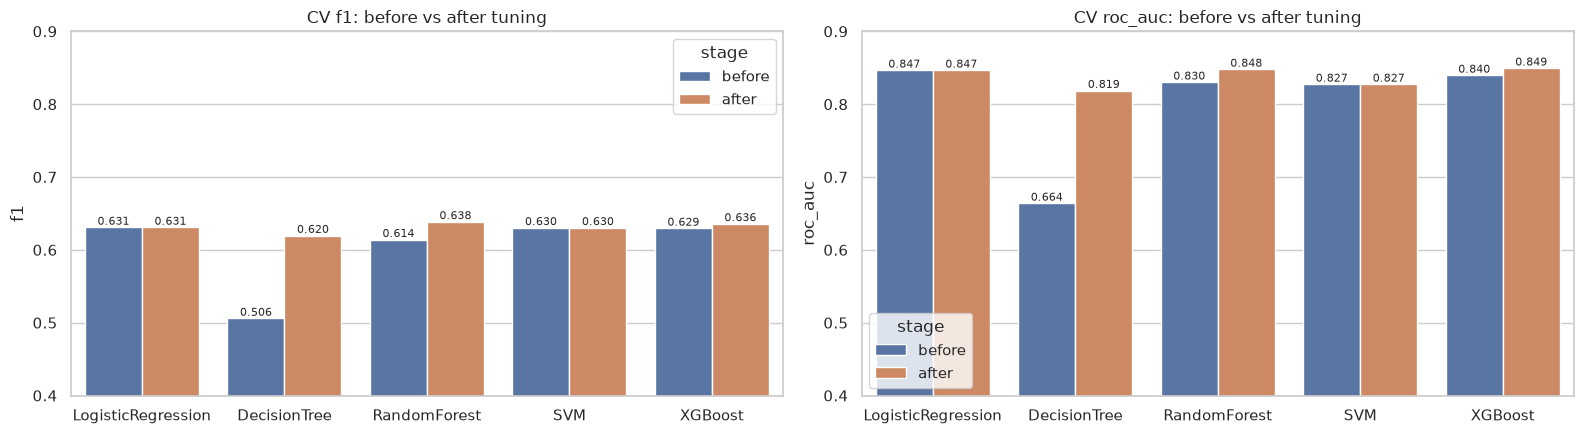

In [12]:
plot_df = pd.concat([before.assign(stage="before"), after.assign(stage="after")]).reset_index(names="model")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, metric in zip(axes, ["f1", "roc_auc"]):
    sns.barplot(data=plot_df, x="model", y=metric, hue="stage", ax=ax)
    ax.set(title=f"CV {metric}: before vs after tuning", xlabel="", ylim=(0.4, 0.9))
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8)
plt.tight_layout()
tuning_fig = fig
plt.show()

Test-set metrics of the tuned models (the test set was never used for tuning):

In [13]:
tuned_test = pd.DataFrame({name: evaluate(searches[name].best_estimator_, X_test, y_test)
                           for name in MODEL_NAMES}).T.sort_values("f1", ascending=False)
tuned_test.round(3)

,precision,recall,f1,roc_auc
RandomForest,0.525,0.785,0.629,0.843
SVM,0.533,0.769,0.629,0.826
XGBoost,0.517,0.785,0.623,0.842
LogisticRegression,0.519,0.780,0.623,0.841
DecisionTree,0.552,0.694,0.615,0.809


Log every tuned model to MLflow (best hyperparameters, CV before/after, test metrics, model).

In [14]:
for name in MODEL_NAMES:
    metrics = {**{f"cv_{m}": after.loc[name, m] for m in after.columns},
               **{f"cv_before_{m}": before.loc[name, m] for m in before.columns},
               **{f"test_{m}": tuned_test.loc[name, m] for m in tuned_test.columns}}
    log_run(f"{name}_tuned", searches[name].best_estimator_, metrics,
            params={"imbalance_strategy": BEST_STRATEGY[name],
                    "search": SEARCH_SPACES[name][0], "search_scoring": "f1", "cv_folds": 5},
            figures={"tuning_before_after": tuning_fig},
            tags={"stage": "tuned", "with_cluster": "false"})

## 4. Contribution of feature engineering and of the cluster
Ablation on the best tuned model (highest CV F1), keeping its hyperparameters fixed:
1. raw variables only (no engineered features);
2. raw + engineered features;
3. raw + engineered features + `cluster`.

In [15]:
best_name = after["f1"].idxmax()
best_params = searches[best_name].best_params_
print("Best tuned model:", best_name, best_params)

variants = {
    "raw variables": dict(feature_engineering=False),
    "raw + feature engineering": dict(feature_engineering=True),
    "raw + FE + cluster": dict(feature_engineering=True, n_clusters=N_CLUSTERS),
}
ablation_rows, ablation_models = [], {}
for label, kwargs in variants.items():
    pipe = build_pipeline(best_name, BEST_STRATEGY[best_name], POS_WEIGHT, **kwargs).set_params(**best_params)
    cv_res = cv_scores(pipe, X_train, y_train, cv)
    pipe.fit(X_train, y_train)
    ablation_models[label] = pipe
    test_res = evaluate(pipe, X_test, y_test)
    ablation_rows.append({"variables": label,
                          **{f"cv_{k}": v for k, v in cv_res.items()},
                          **{f"test_{k}": v for k, v in test_res.items()}})
ablation = pd.DataFrame(ablation_rows).set_index("variables")
ablation.round(3)

Best tuned model: RandomForest {'model__n_estimators': 200, 'model__min_samples_leaf': 20, 'model__max_features': 0.3, 'model__max_depth': 14}


,cv_precision,cv_recall,cv_f1,cv_roc_auc,test_precision,test_recall,test_f1,test_roc_auc
variables,,,,,,,,
raw variables,0.530,0.797,0.637,0.849,0.522,0.785,0.627,0.842
raw + feature engineering,0.532,0.799,0.638,0.848,0.525,0.785,0.629,0.843
raw + FE + cluster,0.532,0.797,0.638,0.847,0.526,0.785,0.630,0.842


In [16]:
for label, pipe in ablation_models.items():
    row = ablation.loc[label]
    log_run(f"{best_name}_ablation_{label.replace(' ', '_').replace('+', 'plus')}", pipe, row.to_dict(),
            params={"variables": label, "imbalance_strategy": BEST_STRATEGY[best_name]},
            tags={"stage": "ablation", "with_cluster": str("cluster" in label).lower()},
            log_model=False)

**Analysis**
- **Tuning**: the largest gain is for the Decision Tree (F1 0.51 → 0.62, ROC-AUC 0.66 → 0.82)
  thanks to `max_depth = 4` which stops overfitting. Random Forest gains +0.02 F1 (shallower
  leaves, `min_samples_leaf = 20`) and becomes the best model; XGBoost gains a little.
  For Logistic Regression and SVM the default hyperparameters were already optimal.
- **Feature engineering**: with the tuned Random Forest, it brings a small, consistent gain
  (+0.001 CV F1, +0.002 test F1). The tree ensemble can already learn most of these
  patterns from the raw columns, but the engineered features are cheap, interpretable and
  help linear models (several are top coefficients in notebook 03).
- **Cluster**: no measurable gain (same CV F1, ±0.001 on test), confirming notebook 04 —
  the segment summarises information the model already has.

## 5. Final model
**Choice: tuned Random Forest** (`class_weight="balanced"`, raw + engineered features):
- best cross-validated F1 after tuning (0.638) and ROC-AUC (0.848);
- outputs a real **churn probability** (needed by the app — SVM does not);
- the `cluster` variable is not included in the model since it adds no performance;
  it is computed separately to display the customer's profile.

In [17]:
final_label = "raw + feature engineering"
final_model = ablation_models[final_label]
final_metrics = evaluate(final_model, X_test, y_test)
print(f"Final model: {best_name} ({BEST_STRATEGY[best_name]}), variables: {final_label}")
print(pd.Series(final_metrics).round(3), "\n")
print(classification_report(y_test, final_model.predict(X_test), target_names=["Stay", "Churn"]))

Final model: RandomForest (class_weight), variables: raw + feature engineering
precision    0.525
recall       0.785
f1           0.629
roc_auc      0.843
dtype: float64 

              precision    recall  f1-score   support

        Stay       0.91      0.74      0.82      1033
       Churn       0.53      0.78      0.63       372

    accuracy                           0.76      1405
   macro avg       0.72      0.76      0.72      1405
weighted avg       0.81      0.76      0.77      1405



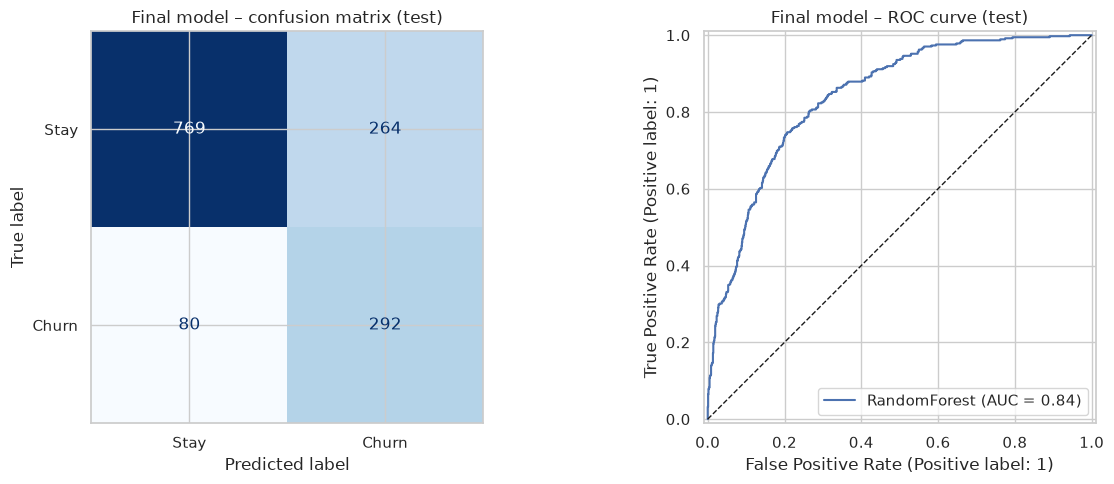

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_estimator(final_model, X_test, y_test, display_labels=["Stay", "Churn"],
                                      cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Final model – confusion matrix (test)")
RocCurveDisplay.from_predictions(y_test, predict_scores(final_model, X_test), name=best_name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("Final model – ROC curve (test)")
plt.tight_layout()
final_fig = fig
plt.show()

Log the final model and register it in the MLflow **Model Registry** as `tele-cluster-churn`.

In [19]:
final_run_id = log_run(
    "FINAL_" + best_name, final_model,
    {**{f"test_{k}": v for k, v in final_metrics.items()},
     **{k: v for k, v in ablation.loc[final_label].items() if k.startswith("cv_")}},
    params={"imbalance_strategy": BEST_STRATEGY[best_name], "variables": final_label},
    figures={"final_evaluation": final_fig, "tuning_before_after": tuning_fig},
    tags={"stage": "final", "with_cluster": "false"})
with mlflow.start_run(run_id=final_run_id):
    mlflow.log_text(comparison.round(4).to_csv(), "before_after_tuning.csv")
    mlflow.log_text(ablation.round(4).to_csv(), "ablation.csv")
registered = mlflow.register_model(f"runs:/{final_run_id}/model", "tele-cluster-churn")
print("Registered model version:", registered.version)

Registered model version: 1


Successfully registered model 'tele-cluster-churn'.
Created version '1' of model 'tele-cluster-churn'.


## 6. Comparing all experiments
All runs of the classification and optimization experiments, sorted by test F1.

In [20]:
runs = mlflow.search_runs(experiment_names=["tele-cluster-classification", "tele-cluster-optimization"],
                          filter_string="metrics.test_f1 > 0")
cols = ["experiment_id", "tags.mlflow.runName", "tags.stage", "params.model", "metrics.cv_f1",
        "metrics.test_precision", "metrics.test_recall", "metrics.test_f1", "metrics.test_roc_auc"]
runs = runs[[c for c in cols if c in runs.columns]].sort_values("metrics.test_f1", ascending=False)
runs.head(15).round(3)

,experiment_id,tags.mlflow.runName,tags.stage,params.model,metrics.cv_f1,metrics.test_precision,metrics.test_recall,metrics.test_f1,metrics.test_roc_auc
1,3,RandomForest_ablation_raw_plus_FE_plus_cluster,ablation,RandomForestClassifier,0.638,0.526,0.785,0.630,0.842
11,2,SVM_cluster,cluster_comparison,SVC,0.630,0.535,0.766,0.630,0.826
2,3,RandomForest_ablation_raw_plus_feature_enginee...,ablation,RandomForestClassifier,0.638,0.525,0.785,0.629,0.843
0,3,FINAL_RandomForest,final,RandomForestClassifier,0.638,0.525,0.785,0.629,0.843
6,3,RandomForest_tuned,tuned,RandomForestClassifier,0.638,0.525,0.785,0.629,0.843
5,3,SVM_tuned,tuned,SVC,0.630,0.533,0.769,0.629,0.826
12,2,SVM_initial,cluster_comparison,SVC,0.630,0.533,0.769,0.629,0.826
20,2,SVM_class_weight,baseline,SVC,0.630,0.533,0.769,0.629,0.826
3,3,RandomForest_ablation_raw_variables,ablation,RandomForestClassifier,0.637,0.522,0.785,0.627,0.842
17,2,LogisticRegression_cluster,cluster_comparison,LogisticRegression,0.632,0.520,0.782,0.624,0.841


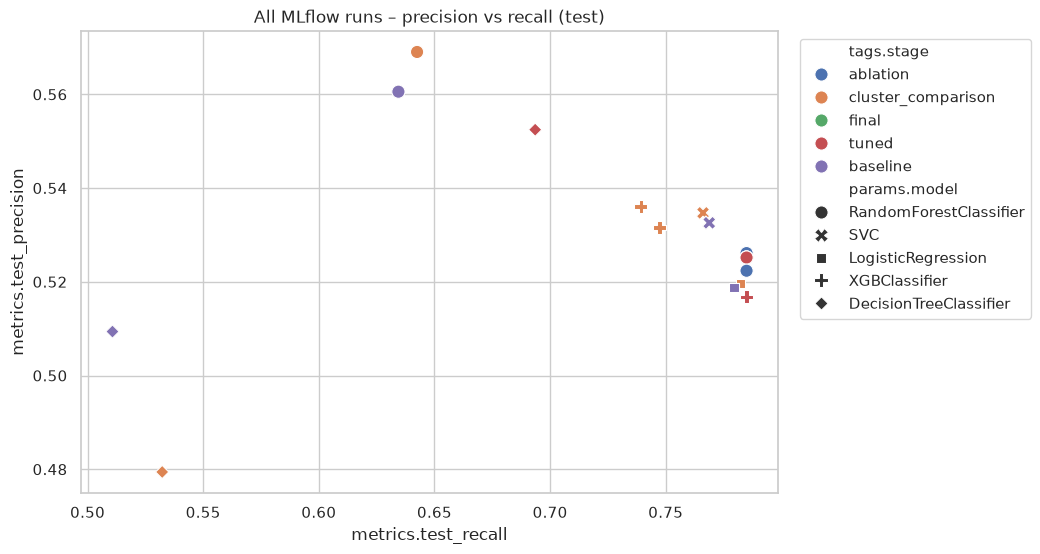

In [21]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=runs, x="metrics.test_recall", y="metrics.test_precision",
                hue="tags.stage", style="params.model", s=90)
plt.title("All MLflow runs – precision vs recall (test)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

The MLflow UI gives the same comparison interactively:
```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

## 7. Save the model & predict a new customer
The final pipeline takes **raw customer columns** as input (feature engineering,
preprocessing and model inside), so it can be used directly by the Streamlit app.
A clustering pipeline fitted on the training customers is saved alongside it to show the
customer's profile.

In [22]:
cluster_pipeline = make_cluster_pipeline(N_CLUSTERS).fit(X_train)
train_cluster = pd.Series(cluster_pipeline.predict(X_train), index=X_train.index)
cluster_info = pd.DataFrame({
    "churn_rate": y_train.groupby(train_cluster).mean(),
    "tenure": X_train["tenure"].groupby(train_cluster).mean(),
    "monthly": X_train["MonthlyCharges"].groupby(train_cluster).mean(),
    "no_internet": (X_train["InternetService"] == "No").groupby(train_cluster).mean(),
})


def name_cluster(c):
    row = cluster_info.loc[c]
    if row["no_internet"] > 0.5:
        return "Basic phone-only"
    if row["tenure"] == cluster_info["tenure"].max():
        return "Loyal premium"
    if row["churn_rate"] == cluster_info["churn_rate"].max():
        return "New fiber, at risk"
    return "Mid-value DSL"


cluster_profiles = {str(c): {"name": name_cluster(c), "churn_rate": round(float(cluster_info.loc[c, "churn_rate"]), 3)}
                    for c in cluster_info.index}

MODELS_DIR.mkdir(exist_ok=True)
with open(MODELS_DIR / "churn_model.pkl", "wb") as f:
    cloudpickle.dump(final_model, f)
with open(MODELS_DIR / "cluster_pipeline.pkl", "wb") as f:
    cloudpickle.dump(cluster_pipeline, f)
(MODELS_DIR / "model_info.json").write_text(json.dumps({
    "model": best_name, "imbalance_strategy": BEST_STRATEGY[best_name], "variables": final_label,
    "hyperparameters": {k: (v.item() if hasattr(v, "item") else v) for k, v in best_params.items()},
    "test_metrics": {k: round(float(v), 4) for k, v in final_metrics.items()},
    "input_columns": list(X_train.columns), "mlflow_run_id": final_run_id,
    "cluster_profiles": cluster_profiles,
}, indent=2))
print("Saved: models/churn_model.pkl, models/cluster_pipeline.pkl, models/model_info.json")
cluster_profiles

Saved: models/churn_model.pkl, models/cluster_pipeline.pkl, models/model_info.json


{'0': {'name': 'Loyal premium', 'churn_rate': 0.149},
 '1': {'name': 'New fiber, at risk', 'churn_rate': 0.576},
 '2': {'name': 'Basic phone-only', 'churn_rate': 0.068},
 '3': {'name': 'Mid-value DSL', 'churn_rate': 0.251}}

**Simulation of the Streamlit app:** reload the saved files and score a new customer.

In [23]:
with open(MODELS_DIR / "churn_model.pkl", "rb") as f:
    model = cloudpickle.load(f)
with open(MODELS_DIR / "cluster_pipeline.pkl", "rb") as f:
    clusterer = cloudpickle.load(f)

new_customer = pd.DataFrame([{
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 3,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "Yes", "StreamingMovies": "No", "Contract": "Month-to-month",
    "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.0, "TotalCharges": 255.0,
}])

cluster = str(clusterer.predict(new_customer)[0])
proba = predict_scores(model, new_customer)[0]
print(f"Profile      : cluster {cluster} – {cluster_profiles[cluster]['name']}")
print(f"Prediction   : {'CHURN' if model.predict(new_customer)[0] == 1 else 'STAY'}")
print(f"Churn proba  : {proba:.1%}" if hasattr(model, "predict_proba") else f"Churn score: {proba:.2f}")

Profile      : cluster 1 – New fiber, at risk
Prediction   : CHURN
Churn proba  : 86.7%


## Summary
| Step | Result |
| --- | --- |
| Tuning (GridSearchCV / RandomizedSearchCV, 5-fold CV, F1) | big gain for Decision Tree, +0.02 F1 for Random Forest |
| Feature engineering | small positive gain |
| Cluster variable | no significant gain (useful for interpretation only) |
| **Final model** | tuned Random Forest — test **recall 0.79, precision 0.53, F1 0.63, ROC-AUC 0.84** |

All experiments (hyperparameters, preprocessing parameters, metrics, figures, models) are
tracked in MLflow; the final model is registered as `tele-cluster-churn` and saved in
`models/` for the Streamlit app.